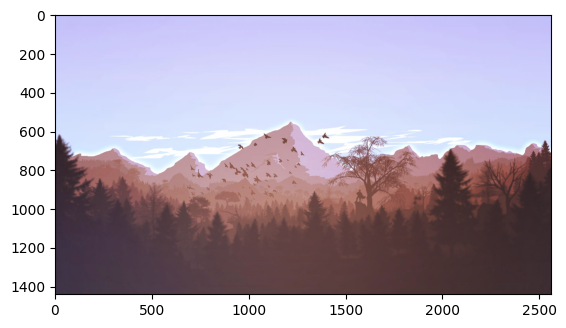

In [25]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.fft import fft2, ifft2, fftshift, ifftshift, dct

IMAGE_PATH  = './mountains.jpg'
TARGET_SIZE = 512

img = cv2.imread('./mountains.jpg')
plt.imshow(img, cmap='gray', vmin=0, vmax=255)

---
## Problem 1 — Image Sampling and Quantization

1. Simulate spatial *sampling* (down-sample then up-sample) and amplitude *quantization* (reduce bit depth).
2. Plot intensity histograms to show how quantization bins the distribution.

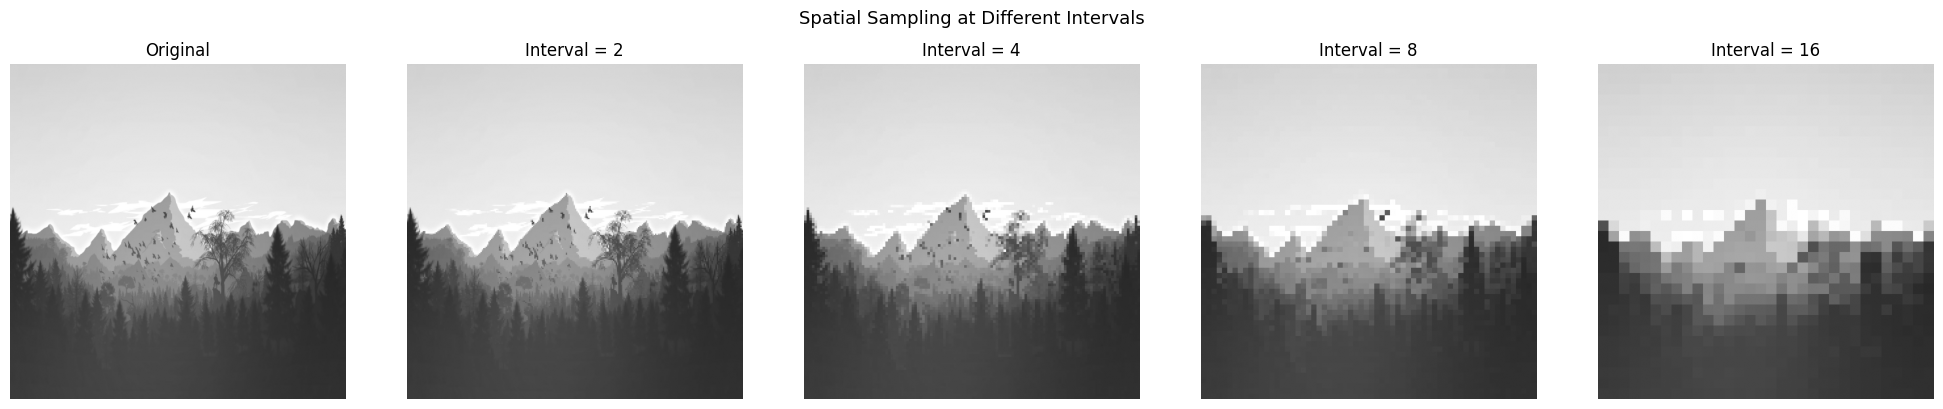

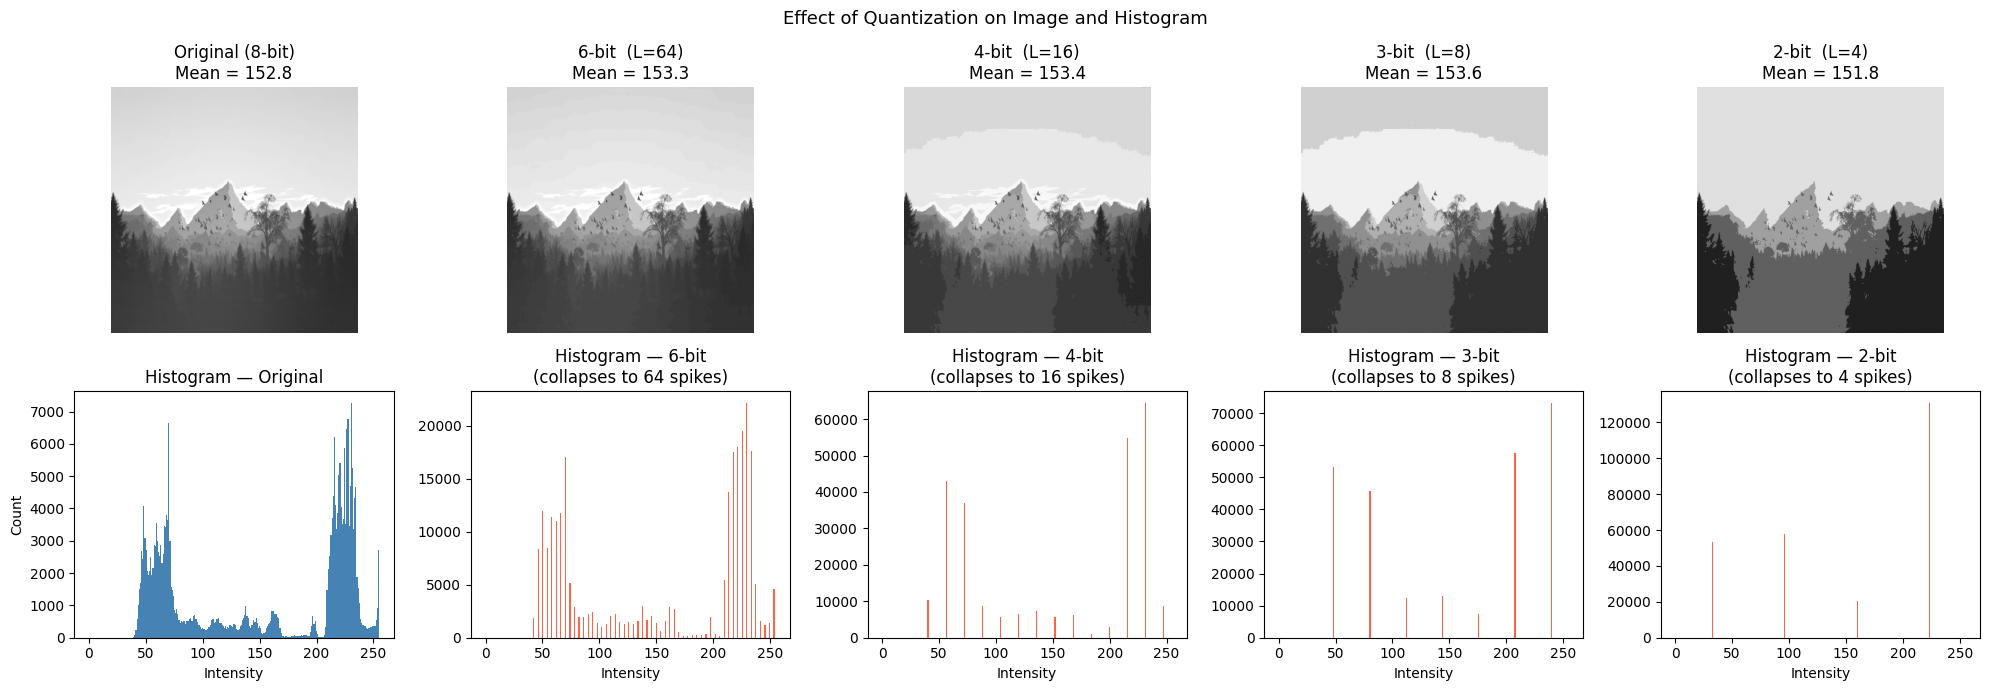

In [17]:
def sample_image(image, sampling_interval):
    h, w = image.shape
    small   = image[::sampling_interval, ::sampling_interval]
    sampled = cv2.resize(small, (w, h), interpolation=cv2.INTER_NEAREST)
    return sampled


def quantize_image(image, num_levels):
    step          = 256.0 / num_levels
    bins          = np.floor(image.astype(np.float64) / step).astype(np.int32)
    reconstructed = bins * step + step / 2.0   # reconstruct from bin midpoints
    return np.clip(reconstructed, 0, 255).astype(np.uint8)


intervals = [2, 4, 8, 16]
fig, axes = plt.subplots(1, len(intervals) + 1, figsize=(4 * (len(intervals) + 1), 4))
axes[0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Original'); axes[0].axis('off')
for ax, s in zip(axes[1:], intervals):
    ax.imshow(sample_image(img, s), cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Interval = {s}'); ax.axis('off')
plt.suptitle('Spatial Sampling at Different Intervals', fontsize=13, y=1.01)
plt.tight_layout(); plt.show()


bit_depths = [6, 4, 3, 2]
n_cols = len(bit_depths) + 1
fig, axes = plt.subplots(2, n_cols, figsize=(4 * n_cols, 7))

axes[0, 0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title(f'Original (8-bit)\nMean = {img.mean():.1f}'); axes[0, 0].axis('off')
axes[1, 0].hist(img.ravel(), bins=256, range=(0, 255), color='steelblue', edgecolor='none')
axes[1, 0].set_xlabel('Intensity'); axes[1, 0].set_ylabel('Count')
axes[1, 0].set_title('Histogram — Original')

for col, bits in enumerate(bit_depths, start=1):
    L = 2 ** bits
    q = quantize_image(img, L)
    axes[0, col].imshow(q, cmap='gray', vmin=0, vmax=255)
    axes[0, col].set_title(f'{bits}-bit  (L={L})\nMean = {q.mean():.1f}'); axes[0, col].axis('off')
    axes[1, col].hist(q.ravel(), bins=256, range=(0, 255), color='tomato', edgecolor='none')
    axes[1, col].set_xlabel('Intensity')
    axes[1, col].set_title(f'Histogram — {bits}-bit\n(collapses to {L} spikes)')

plt.suptitle('Effect of Quantization on Image and Histogram', fontsize=13)
plt.tight_layout(); plt.show()

---
## Problem 2 — Discrete Transforms: DCT and FFT

1. Apply 1-D FFT along rows and columns independently, then compute 2-D FFT magnitude spectrum.
2. Compute 2-D DCT. Compare energy compaction of DCT vs FFT and explain JPEG preference.

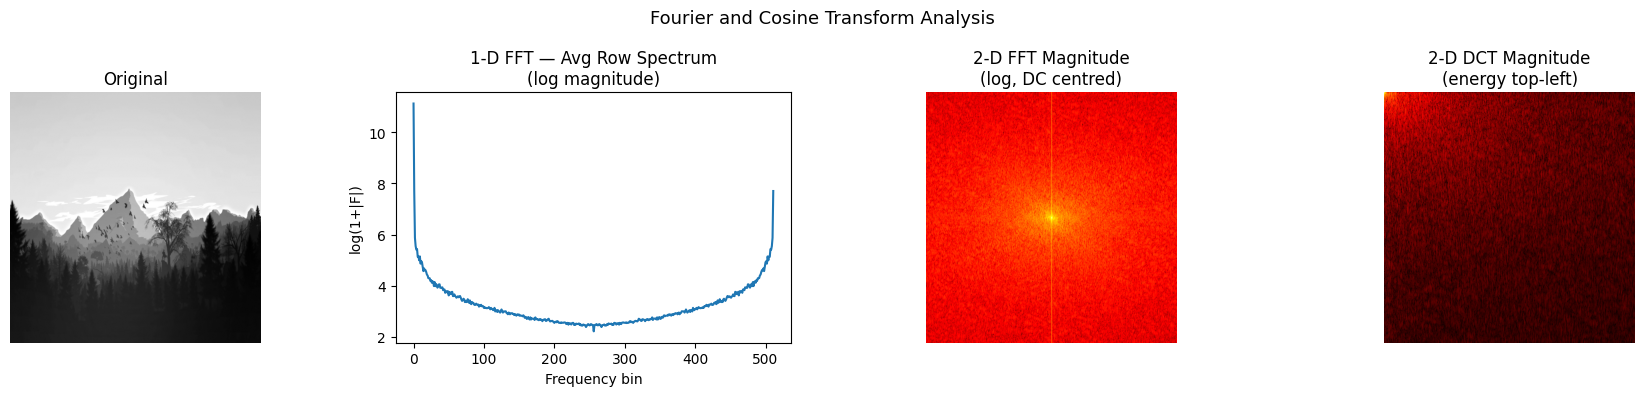

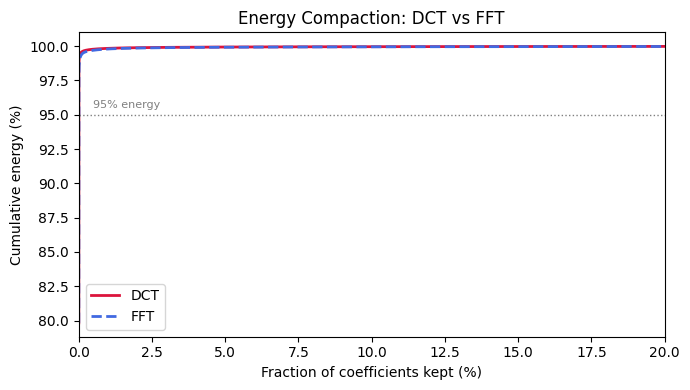

DCT: 0.00% of coefficients needed for 95% energy
FFT: 0.00% of coefficients needed for 95% energy


In [18]:
f64 = img.astype(np.float64)

F_rows = np.fft.fft(f64, axis=1)
F_2d   = np.fft.fft(F_rows, axis=0)

spectrum_2d = np.log1p(np.abs(fftshift(F_2d)))

row_spec = np.log1p(np.abs(F_rows)).mean(axis=0)

D_2d = dct(dct(f64, axis=1, norm='ortho'), axis=0, norm='ortho')

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].imshow(img, cmap='gray'); axes[0].set_title('Original'); axes[0].axis('off')
axes[1].plot(row_spec); axes[1].set_title('1-D FFT — Avg Row Spectrum\n(log magnitude)')
axes[1].set_xlabel('Frequency bin'); axes[1].set_ylabel('log(1+|F|)')
axes[2].imshow(spectrum_2d, cmap='hot'); axes[2].set_title('2-D FFT Magnitude\n(log, DC centred)'); axes[2].axis('off')
axes[3].imshow(np.log1p(np.abs(D_2d)), cmap='hot'); axes[3].set_title('2-D DCT Magnitude\n(energy top-left)'); axes[3].axis('off')
plt.suptitle('Fourier and Cosine Transform Analysis', fontsize=13)
plt.tight_layout(); plt.show()

dct_power = np.sort(D_2d.ravel() ** 2)[::-1]
fft_power = np.sort(np.abs(F_2d.ravel()) ** 2)[::-1]
frac      = np.arange(1, len(dct_power) + 1) / len(dct_power) * 100

plt.figure(figsize=(7, 4))
plt.plot(frac, np.cumsum(dct_power) / dct_power.sum() * 100, label='DCT', color='crimson',   lw=2)
plt.plot(frac, np.cumsum(fft_power) / fft_power.sum() * 100, label='FFT', color='royalblue', lw=2, ls='--')
plt.axhline(95, color='gray', ls=':', lw=1)
plt.text(0.5, 95.5, '95% energy', color='gray', fontsize=8)
plt.xlim(0, 20); plt.xlabel('Fraction of coefficients kept (%)')
plt.ylabel('Cumulative energy (%)'); plt.title('Energy Compaction: DCT vs FFT'); plt.legend()
plt.tight_layout(); plt.show()

for name, power in [('DCT', dct_power), ('FFT', fft_power)]:
    idx = np.searchsorted(np.cumsum(power) / power.sum() * 100, 95)
    print(f'{name}: {idx / len(power) * 100:.2f}% of coefficients needed for 95% energy')

---
## Problem 3 — Frequency Domain Smoothing (Lowpass Filters)

Implement ILPF, BLPF, and GLPF and compare blurring behaviour.

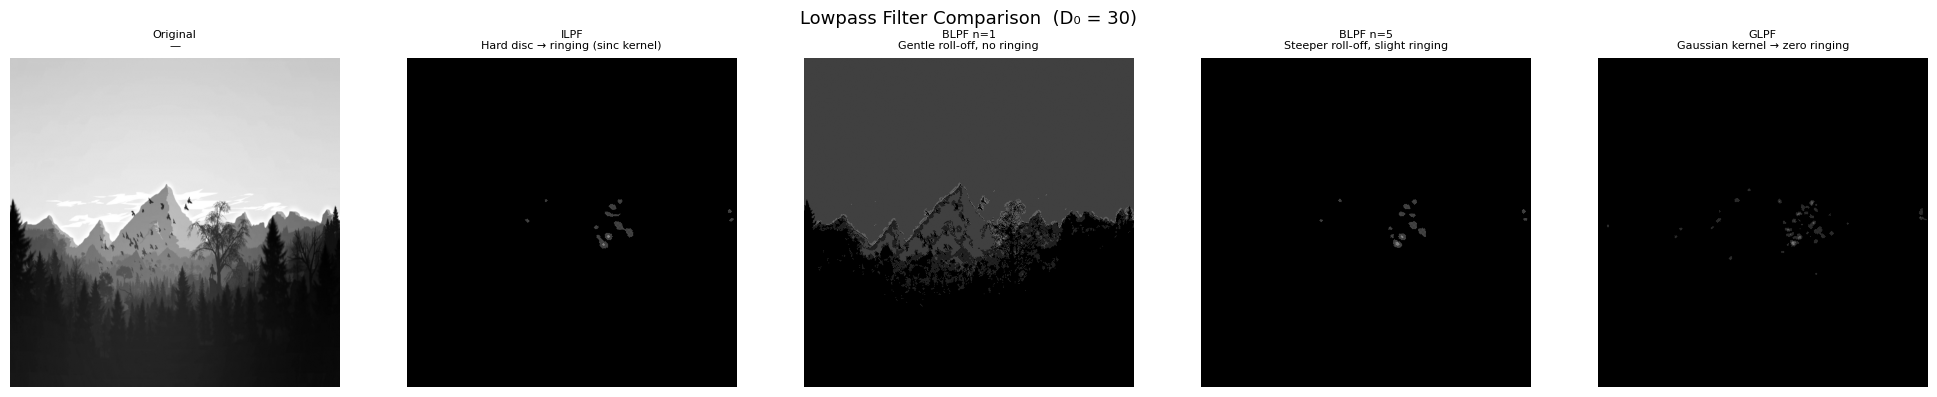

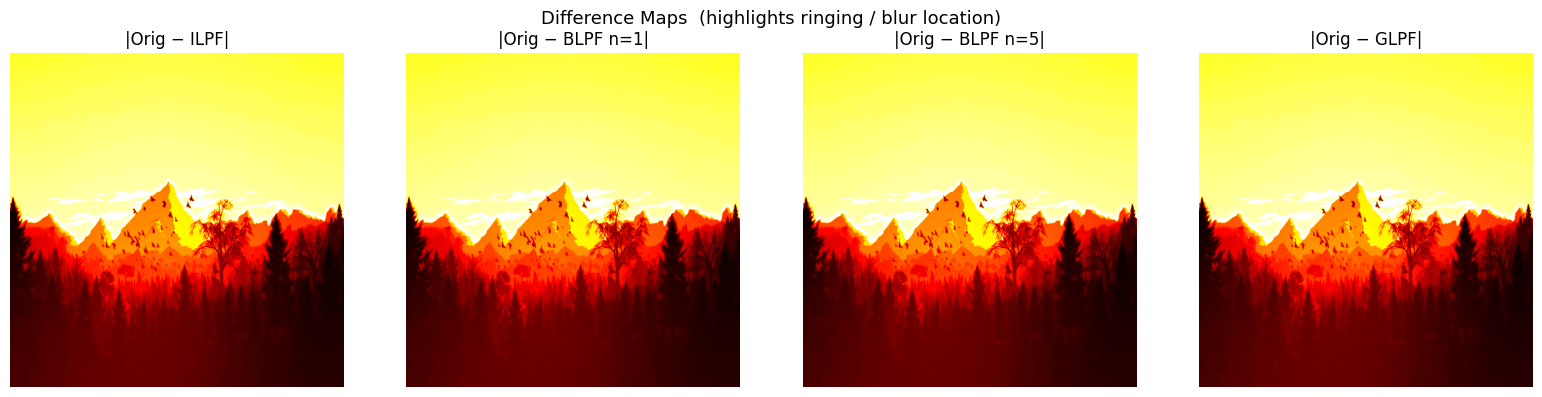

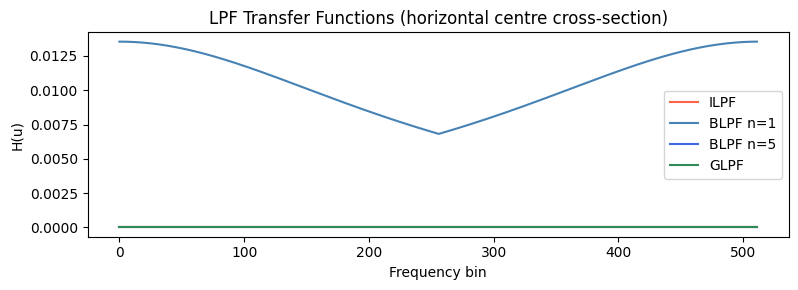

In [19]:
def distance_matrix(shape):
    H, W = shape
    u = np.fft.fftfreq(H) * H
    v = np.fft.fftfreq(W) * W
    U, V = np.meshgrid(u, v, indexing='ij')
    return np.sqrt(U ** 2 + V ** 2)


def apply_freq_filter(image, H_filter):
    F      = fftshift(fft2(image.astype(np.float64)))
    result = np.real(ifft2(ifftshift(F * H_filter)))
    return np.clip(result, 0, 255).astype(np.uint8)


D0 = 30
D  = distance_matrix(img.shape)

H_ilpf  = (D <= D0).astype(np.float64)

H_blpf1 = 1.0 / (1.0 + (D / D0) ** 2)
H_blpf5 = 1.0 / (1.0 + (D / D0) ** 10)

H_glpf  = np.exp(-(D ** 2) / (2 * D0 ** 2))

results = [
    ('Original',  img,                             '—'),
    ('ILPF',      apply_freq_filter(img, H_ilpf),  'Hard disc → ringing (sinc kernel)'),
    ('BLPF n=1',  apply_freq_filter(img, H_blpf1), 'Gentle roll-off, no ringing'),
    ('BLPF n=5',  apply_freq_filter(img, H_blpf5), 'Steeper roll-off, slight ringing'),
    ('GLPF',      apply_freq_filter(img, H_glpf),  'Gaussian kernel → zero ringing'),
]

fig, axes = plt.subplots(1, len(results), figsize=(4 * len(results), 4))
for ax, (label, result, note) in zip(axes, results):
    ax.imshow(result, cmap='gray'); ax.set_title(f'{label}\n{note}', fontsize=8); ax.axis('off')
plt.suptitle(f'Lowpass Filter Comparison  (D₀ = {D0})', fontsize=13)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(results) - 1, figsize=(4 * (len(results) - 1), 4))
for ax, (label, result, _) in zip(axes, results[1:]):
    diff = np.abs(img.astype(np.int16) - result.astype(np.int16))
    ax.imshow(diff, cmap='hot'); ax.set_title(f'|Orig − {label}|'); ax.axis('off')
plt.suptitle('Difference Maps  (highlights ringing / blur location)', fontsize=13)
plt.tight_layout(); plt.show()

mid = img.shape[0] // 2
plt.figure(figsize=(8, 3))
for H, label, color in [
    (H_ilpf,  'ILPF',      'tomato'),
    (H_blpf1, 'BLPF n=1',  'steelblue'),
    (H_blpf5, 'BLPF n=5',  'royalblue'),
    (H_glpf,  'GLPF',      'seagreen'),
]:
    plt.plot(H[mid, :], label=label, color=color)
plt.xlabel('Frequency bin'); plt.ylabel('H(u)')
plt.title('LPF Transfer Functions (horizontal centre cross-section)')
plt.legend(); plt.tight_layout(); plt.show()

---
## Problem 4 — Frequency Domain Sharpening (Highpass Filters)

1. Extract edge information using Ideal and Butterworth HPFs.
2. Implement High-Boost Filtering to sharpen while preserving the original tonal background.

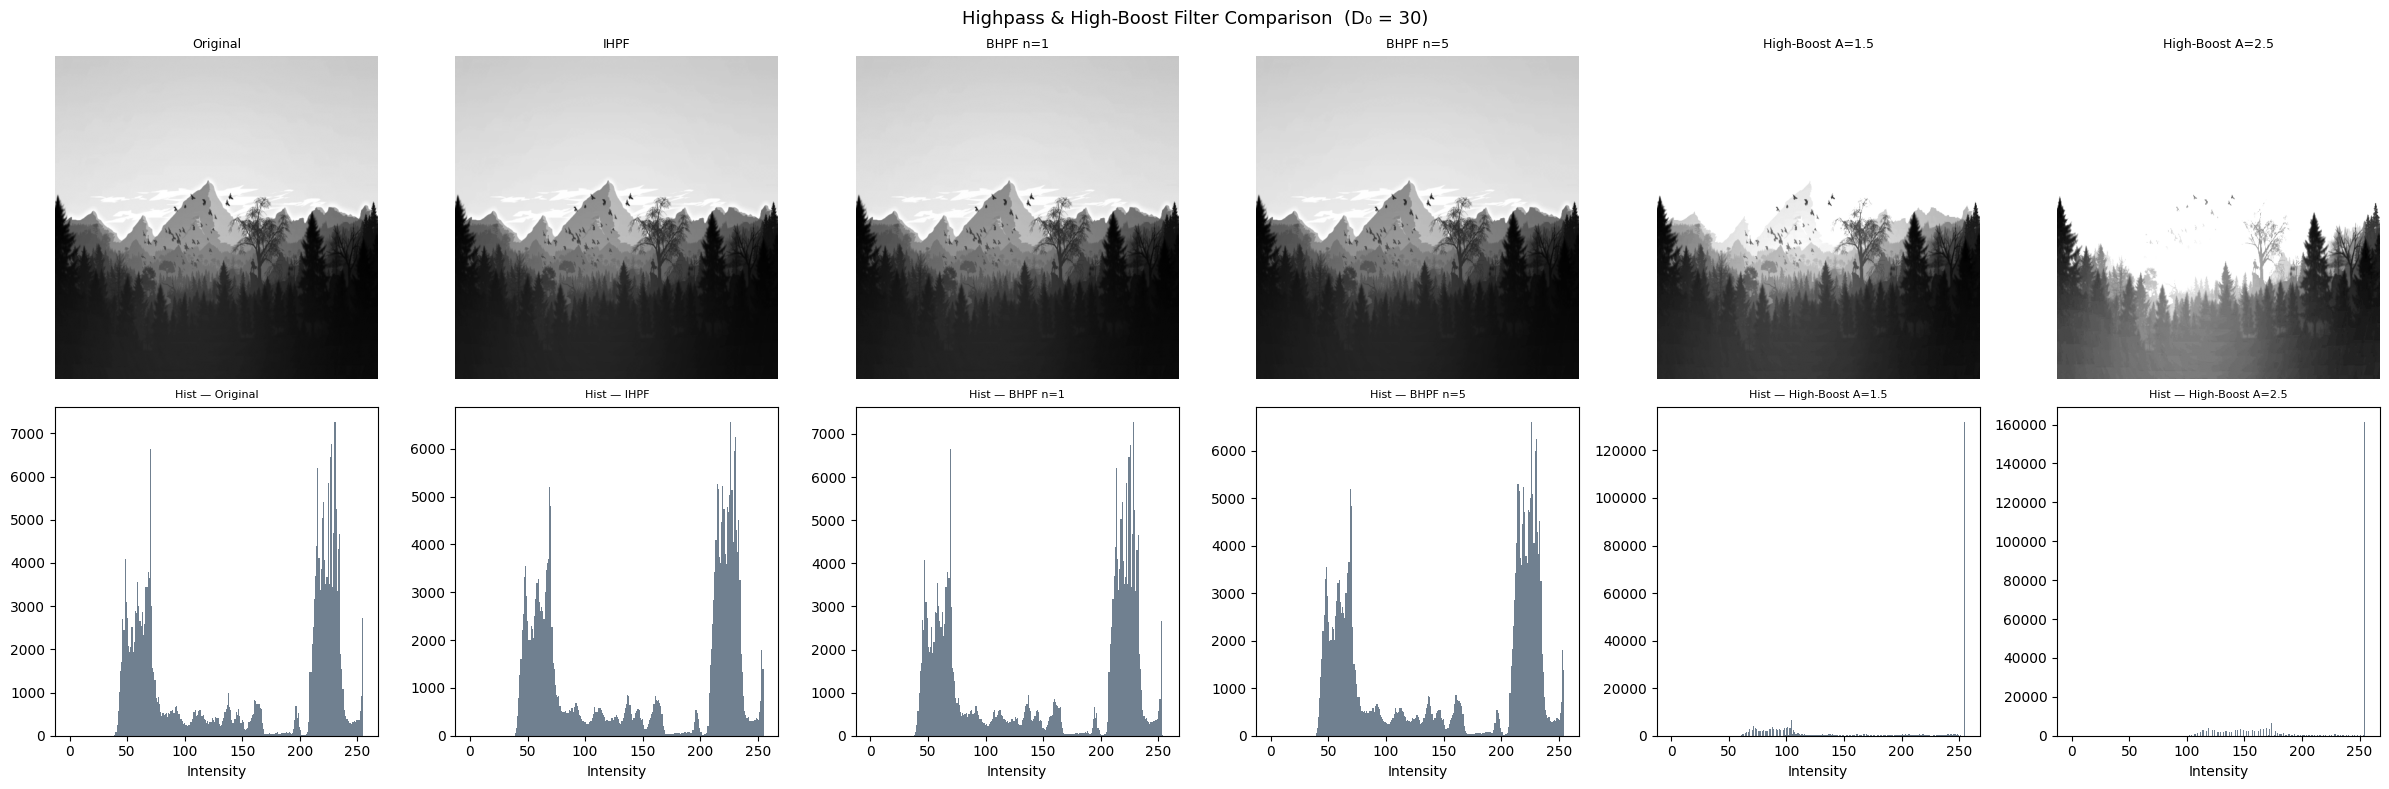

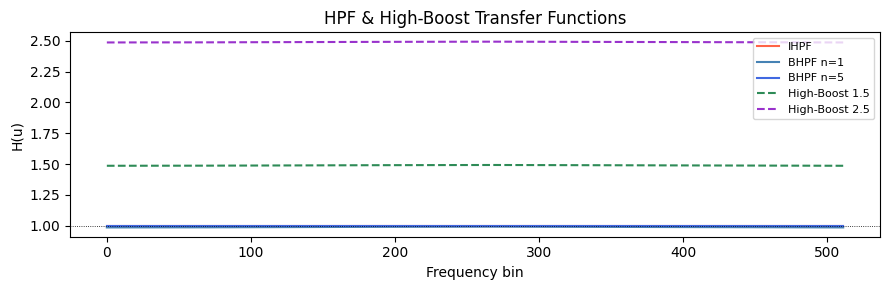

In [20]:
H_ihpf  = 1.0 - H_ilpf
H_bhpf1 = 1.0 - H_blpf1
H_bhpf5 = 1.0 - H_blpf5

H_hb15 = 1.5 - H_blpf1
H_hb25 = 2.5 - H_blpf1

hpf_results = [
    ('Original',         img),
    ('IHPF',             apply_freq_filter(img, H_ihpf)),
    ('BHPF n=1',         apply_freq_filter(img, H_bhpf1)),
    ('BHPF n=5',         apply_freq_filter(img, H_bhpf5)),
    ('High-Boost A=1.5', apply_freq_filter(img, H_hb15)),
    ('High-Boost A=2.5', apply_freq_filter(img, H_hb25)),
]

fig, axes = plt.subplots(2, len(hpf_results), figsize=(4 * len(hpf_results), 8))
for col, (label, result) in enumerate(hpf_results):
    axes[0, col].imshow(result, cmap='gray')
    axes[0, col].set_title(label, fontsize=9); axes[0, col].axis('off')
    axes[1, col].hist(result.ravel(), bins=256, range=(0, 255),
                      color='slategray', edgecolor='none')
    axes[1, col].set_title(f'Hist — {label}', fontsize=8)
    axes[1, col].set_xlabel('Intensity')
plt.suptitle(f'Highpass & High-Boost Filter Comparison  (D₀ = {D0})', fontsize=13)
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 3))
for H, label, color, ls in [
    (H_ihpf,  'IHPF',           'tomato',    '-'),
    (H_bhpf1, 'BHPF n=1',       'steelblue', '-'),
    (H_bhpf5, 'BHPF n=5',       'royalblue', '-'),
    (H_hb15,  'High-Boost 1.5', 'seagreen',  '--'),
    (H_hb25,  'High-Boost 2.5', 'darkorchid','--'),
]:
    plt.plot(H[mid, :], label=label, color=color, ls=ls)
plt.axhline(1.0, color='black', lw=0.6, ls=':')
plt.xlabel('Frequency bin'); plt.ylabel('H(u)')
plt.title('HPF & High-Boost Transfer Functions')
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

---
## Problem 5 — Homomorphic Filtering

Correct non-uniform illumination using the log-domain illumination-reflectance model.  

An artificial illumination gradient is applied to the loaded image so the correction effect is dramatic regardless of the source photo.

Non-uniform image  — left-quarter mean: 28.9  right-quarter mean: 116.7
Corrected image    — left-quarter mean: 213.9  right-quarter mean: 255.0


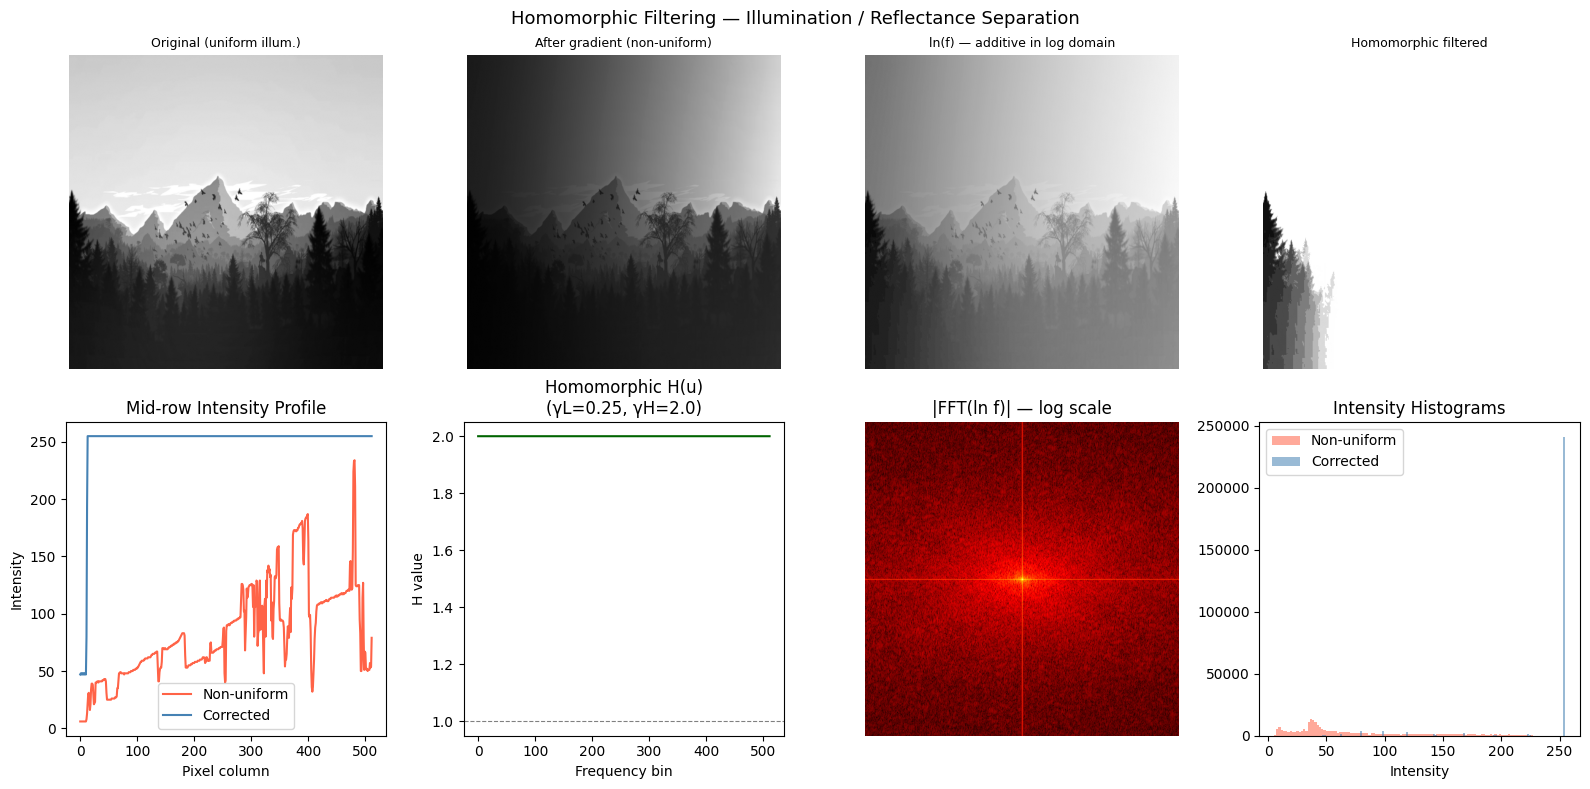

In [21]:
H_sz, W_sz = img.shape
_, x_grid  = np.mgrid[0:H_sz, 0:W_sz]
illum_mask = 0.15 + 0.85 * (x_grid / W_sz) ** 1.5
dark_img   = np.clip(img.astype(np.float64) * illum_mask, 1, 255).astype(np.uint8)

print('Non-uniform image  — '
      f'left-quarter mean: {dark_img[:, :W_sz//4].mean():.1f}  '
      f'right-quarter mean: {dark_img[:, 3*W_sz//4:].mean():.1f}')


def homomorphic_filter(image, cutoff=30, gamma_low=0.25, gamma_high=2.0, order=2):
    ln_f = np.log1p(image.astype(np.float64))

    F = fftshift(fft2(ln_f))

    D_h   = distance_matrix(image.shape)
    H_lpf = 1.0 / (1.0 + (D_h / cutoff) ** (2 * order))
    H     = (gamma_high - gamma_low) * (1.0 - H_lpf) + gamma_low

    G = F * H

    g = np.real(ifft2(ifftshift(G)))

    corrected = np.clip(np.expm1(g), 0, 255).astype(np.uint8)
    return corrected, H


corrected, H_hm = homomorphic_filter(dark_img)
print('Corrected image    — '
      f'left-quarter mean: {corrected[:, :W_sz//4].mean():.1f}  '
      f'right-quarter mean: {corrected[:, 3*W_sz//4:].mean():.1f}')

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, (data, title) in zip(axes[0], [
    (img,                                   'Original (uniform illum.)'),
    (dark_img,                              'After gradient (non-uniform)'),
    (np.log1p(dark_img.astype(float)),      'ln(f) — additive in log domain'),
    (corrected,                             'Homomorphic filtered'),
]):
    ax.imshow(data, cmap='gray'); ax.set_title(title, fontsize=9); ax.axis('off')

row = H_sz // 2
axes[1, 0].plot(dark_img[row, :],  label='Non-uniform', color='tomato')
axes[1, 0].plot(corrected[row, :], label='Corrected',   color='steelblue')
axes[1, 0].set_title('Mid-row Intensity Profile')
axes[1, 0].set_xlabel('Pixel column'); axes[1, 0].set_ylabel('Intensity'); axes[1, 0].legend()

mid_h = H_hm.shape[0] // 2
axes[1, 1].plot(H_hm[mid_h, :], color='darkgreen')
axes[1, 1].axhline(1.0, color='gray', ls='--', lw=0.8)
axes[1, 1].set_title('Homomorphic H(u)\n(γL=0.25, γH=2.0)')
axes[1, 1].set_xlabel('Frequency bin'); axes[1, 1].set_ylabel('H value')

F_log = fftshift(fft2(np.log1p(dark_img.astype(float))))
axes[1, 2].imshow(np.log1p(np.abs(F_log)), cmap='hot')
axes[1, 2].set_title('|FFT(ln f)| — log scale'); axes[1, 2].axis('off')

axes[1, 3].hist(dark_img.ravel(),  bins=128, alpha=0.55, label='Non-uniform', color='tomato')
axes[1, 3].hist(corrected.ravel(), bins=128, alpha=0.55, label='Corrected',   color='steelblue')
axes[1, 3].set_title('Intensity Histograms')
axes[1, 3].set_xlabel('Intensity'); axes[1, 3].legend()

plt.suptitle('Homomorphic Filtering — Illumination / Reflectance Separation', fontsize=13)
plt.tight_layout(); plt.show()